In [4]:
import torch
import torch.nn as nn
from torchvision import datasets,transforms
from torch.utils.data import DataLoader
from torch.utils.data import random_split
from pathlib import Path

In [2]:
train_dataset = datasets.FashionMNIST(
    root="../../data",
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

loaded_data = DataLoader(train_dataset,batch_size=32,shuffle= True,num_workers= 0 )

In [3]:
train_subset, val_subset = random_split(
    train_dataset,
    [54000, 6000],
    generator=torch.Generator().manual_seed(42),
)
train_set = DataLoader(train_subset,batch_size=32,shuffle= True,num_workers= 0 )
val_set = DataLoader(val_subset,batch_size=32,shuffle= False,num_workers= 0 )

In [7]:
class classimodel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(784,128)
        self.layer2 = nn.Linear(128,10)

    def forward(self,x):
        input = x.flatten(start_dim = 1)
        y1 = self.layer1(input)
        y2 = torch.relu(y1)
        y3 = self.layer2(y2)
        return y3
model = classimodel()
optimizer = torch.optim.SGD(model.parameters(),lr= 0.1)
loss_api = nn.CrossEntropyLoss()
model.train()

epochs = 1

for epoch in range(epochs):
    total_loss = 0.0
    correct_num = 0
    total_num = 0

    for batch_index , (images,labels) in enumerate(train_set):
        optimizer.zero_grad(set_to_none=True)
        prediction = model(images)
        loss = loss_api(prediction,labels)
        loss.backward()
        optimizer.step()

        the_label = prediction.argmax(dim = 1)
        correct_num += (the_label == labels).sum().item()
        total_num += labels.shape[0]
        total_loss += loss.item() * labels.shape[0]

        if (batch_index + 1) % 300 == 0 or (batch_index + 1 == len(train_set)):
            print(
                f"Epoch {epoch + 1}/{epochs}, "
                f"Batch {batch_index + 1}/{len(train_set)}, "
                f"batch_loss={loss.item():.4f}"
            )
    acc = correct_num / total_num
    av_loss = total_loss / total_num
    print(
            f"Epoch {epoch + 1}: "
            f"correct={correct_num}, total={total_num}, "
            f"accuracy={acc:.2%},"
            f"av_loss={av_loss:.6f}"
        )
    

Epoch 1/1, Batch 300/1688, batch_loss=0.4873
Epoch 1/1, Batch 600/1688, batch_loss=0.3900
Epoch 1/1, Batch 900/1688, batch_loss=0.4676
Epoch 1/1, Batch 1200/1688, batch_loss=0.3323
Epoch 1/1, Batch 1500/1688, batch_loss=0.5472
Epoch 1/1, Batch 1688/1688, batch_loss=0.2473
Epoch 1: correct=42884, total=54000, accuracy=79.41%,av_loss=0.573088


In [8]:
model.eval()
val_total_num = 0
val_correct_num = 0
val_total_loss = 0.0
with torch.no_grad():
    for images,labels in (val_set):
        prediction_infer = model(images)
        loss = loss_api(prediction_infer,labels)

        the_infer_labels = prediction_infer.argmax(dim = 1)
        val_correct_num += (the_infer_labels == labels).sum().item()
        val_total_num += labels.shape[0]
        val_total_loss += loss.item() * labels.shape[0]

    av_val_loss = val_total_loss / val_total_num
    accuracy = val_correct_num / val_total_num
    print("acc:",accuracy)
    print("av_val_loss",av_val_loss)


acc: 0.8345
av_val_loss 0.4693491555849711


In [9]:
print(val_total_num)

6000


In [5]:
class classimodel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(784,128)
        self.layer2 = nn.Linear(128,10)

    def forward(self,x):
        input = x.flatten(start_dim = 1)
        y1 = self.layer1(input)
        y2 = torch.relu(y1)
        y3 = self.layer2(y2)
        return y3
model = classimodel()
optimizer = torch.optim.SGD(model.parameters(),lr= 0.1)
loss_api = nn.CrossEntropyLoss()

train_av_loss = []
val_av_loss = []
train_acc = []
val_ac = []



epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    correct_num = 0
    total_num = 0

    for batch_index , (images,labels) in enumerate(train_set):
        optimizer.zero_grad(set_to_none=True)
        prediction = model(images)
        loss = loss_api(prediction,labels)
        loss.backward()
        optimizer.step()

        the_label = prediction.argmax(dim = 1)
        correct_num += (the_label == labels).sum().item()
        total_num += labels.shape[0]
        total_loss += loss.item() * labels.shape[0]

    acc = correct_num / total_num
    av_loss = total_loss / total_num
    
    train_acc.append(acc)
    train_av_loss.append(av_loss)



    model.eval()
    val_total_num = 0
    val_correct_num = 0
    val_total_loss = 0.0
    with torch.no_grad():
        for images,labels in (val_set):
            prediction_infer = model(images)
            loss = loss_api(prediction_infer,labels)

            the_infer_labels = prediction_infer.argmax(dim = 1)
            val_correct_num += (the_infer_labels == labels).sum().item()
            val_total_num += labels.shape[0]
            val_total_loss += loss.item() * labels.shape[0]

    av_val_loss = val_total_loss / val_total_num
    accuracy = val_correct_num / val_total_num

    val_ac.append(accuracy)
    val_av_loss.append(av_val_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"train_loss={av_loss:.4f}, train_acc={acc:.2%} | "
        f"val_loss={av_val_loss:.4f}, val_acc={accuracy:.2%} | "
        f"samples={total_num}/{val_total_num}"
    )

print(
    "History lengths:",
    len(train_av_loss),
    len(val_av_loss),
    len(train_acc),
    len(val_ac),
)

Epoch 1/5 | train_loss=0.5733, train_acc=79.69% | val_loss=0.4431, val_acc=84.28% | samples=54000/6000
Epoch 2/5 | train_loss=0.4114, train_acc=85.14% | val_loss=0.4093, val_acc=85.08% | samples=54000/6000
Epoch 3/5 | train_loss=0.3726, train_acc=86.29% | val_loss=0.3951, val_acc=85.82% | samples=54000/6000
Epoch 4/5 | train_loss=0.3449, train_acc=87.44% | val_loss=0.3559, val_acc=87.23% | samples=54000/6000
Epoch 5/5 | train_loss=0.3286, train_acc=87.99% | val_loss=0.4286, val_acc=84.53% | samples=54000/6000
History lengths: 5 5 5 5


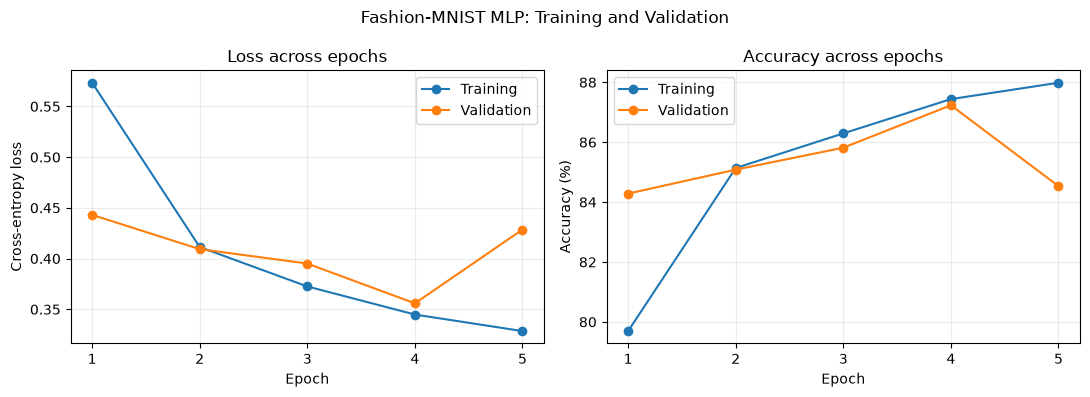

In [6]:
import matplotlib.pyplot as plt

epoch_numbers = range(1, len(train_av_loss) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epoch_numbers, train_av_loss, marker="o", label="Training")
axes[0].plot(epoch_numbers, val_av_loss, marker="o", label="Validation")
axes[0].set_title("Loss across epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")

axes[1].plot(
    epoch_numbers,
    [value * 100 for value in train_acc],
    marker="o",
    label="Training",
)
axes[1].plot(
    epoch_numbers,
    [value * 100 for value in val_ac],
    marker="o",
    label="Validation",
)
axes[1].set_title("Accuracy across epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.set_xticks(list(epoch_numbers))
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle("Fashion-MNIST MLP: Training and Validation")
fig.tight_layout()
plt.show()

In [5]:
class classimodel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(784,128)
        self.layer2 = nn.Linear(128,10)

    def forward(self,x):
        input = x.flatten(start_dim = 1)
        y1 = self.layer1(input)
        y2 = torch.relu(y1)
        y3 = self.layer2(y2)
        return y3
model = classimodel()
optimizer = torch.optim.SGD(model.parameters(),lr= 0.1)
loss_api = nn.CrossEntropyLoss()

train_av_loss = []
val_av_loss = []
train_acc = []
val_ac = []

best_val_acc = -1.0
best_epoch = 0

checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = checkpoint_dir / "fashion_mnist_best.pt"

epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    correct_num = 0
    total_num = 0

    


    for batch_index , (images,labels) in enumerate(train_set):
        optimizer.zero_grad(set_to_none=True)
        prediction = model(images)
        loss = loss_api(prediction,labels)
        loss.backward()
        optimizer.step()

        the_label = prediction.argmax(dim = 1)
        correct_num += (the_label == labels).sum().item()
        total_num += labels.shape[0]
        total_loss += loss.item() * labels.shape[0]

    acc = correct_num / total_num
    av_loss = total_loss / total_num
    
    train_acc.append(acc)
    train_av_loss.append(av_loss)



    model.eval()
    val_total_num = 0
    val_correct_num = 0
    val_total_loss = 0.0
    with torch.no_grad():
        for images,labels in (val_set):
            prediction_infer = model(images)
            loss = loss_api(prediction_infer,labels)

            the_infer_labels = prediction_infer.argmax(dim = 1)
            val_correct_num += (the_infer_labels == labels).sum().item()
            val_total_num += labels.shape[0]
            val_total_loss += loss.item() * labels.shape[0]

    av_val_loss = val_total_loss / val_total_num
    accuracy = val_correct_num / val_total_num

    val_ac.append(accuracy)
    val_av_loss.append(av_val_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"train_loss={av_loss:.4f}, train_acc={acc:.2%} | "
        f"val_loss={av_val_loss:.4f}, val_acc={accuracy:.2%} | "
        f"samples={total_num}/{val_total_num}"
    )
    if accuracy > best_val_acc:
        best_val_acc = accuracy
        best_epoch = epoch + 1

        torch.save(model.state_dict(), checkpoint_path)

        print(
            f"Saved best model: epoch={best_epoch}, "
            f"val_acc={best_val_acc:.2%}"
        )


print(
    "History lengths:",
    len(train_av_loss),
    len(val_av_loss),
    len(train_acc),
    len(val_ac),
    "best_epoch:",best_epoch,
    "best_val_acc:",best_val_acc
)

Epoch 1/5 | train_loss=0.5785, train_acc=79.30% | val_loss=0.5363, val_acc=80.12% | samples=54000/6000
Saved best model: epoch=1, val_acc=80.12%
Epoch 2/5 | train_loss=0.4152, train_acc=84.88% | val_loss=0.4699, val_acc=83.08% | samples=54000/6000
Saved best model: epoch=2, val_acc=83.08%
Epoch 3/5 | train_loss=0.3722, train_acc=86.53% | val_loss=0.4504, val_acc=82.98% | samples=54000/6000
Epoch 4/5 | train_loss=0.3476, train_acc=87.38% | val_loss=0.3531, val_acc=87.03% | samples=54000/6000
Saved best model: epoch=4, val_acc=87.03%
Epoch 5/5 | train_loss=0.3286, train_acc=88.05% | val_loss=0.3466, val_acc=87.25% | samples=54000/6000
Saved best model: epoch=5, val_acc=87.25%
History lengths: 5 5 5 5 best_epoch: 5 best_val_acc: 0.8725


In [6]:
loaded_model = classimodel()

infer_para = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)
loaded_model.load_state_dict(infer_para)
loaded_model.eval()

val_total_num = 0
val_correct_num = 0
val_total_loss = 0.0

with torch.no_grad():
    for images, labels in val_set:
        prediction_infer = loaded_model(images)
        loss = loss_api(prediction_infer, labels)

        the_infer_labels = prediction_infer.argmax(dim=1)
        val_correct_num += (the_infer_labels == labels).sum().item()
        val_total_num += labels.shape[0]
        val_total_loss += loss.item() * labels.shape[0]

av_val_loss = val_total_loss / val_total_num
accuracy = val_correct_num / val_total_num

print("Validation samples:", val_total_num)
print(f"Loaded model accuracy: {accuracy:.2%}")
print(f"Loaded model average loss: {av_val_loss:.6f}")

Validation samples: 6000
Loaded model accuracy: 87.25%
Loaded model average loss: 0.346610
